### Causal Forest, Double ML and Propensity Score Matching (Full Data)

I run the same models and methods as in `Causal_Forest_DML_PSM.ipynb`, but this time on the **full dataset** (about 14 million customers) instead of the 5% sample used there and in `Modeling_sample_2.ipynb`. The 5% sample had only 42 control conversions in the test set, resulting in very wide confidence intervals. With the full dataset, there should be about 800 control conversions.

When I write "the 5% sample" below, I mean the results in `Causal_Forest_DML_PSM.ipynb`, unless I name `Modeling_sample_2.ipynb`.

- **Propensity score matching (PSM)** estimates the average campaign effect. It cannot rank customers, so I compare it only with the other average effect estimates.
- **Double ML** estimates the average effect and predicts the effect for each customer.
- **Causal forest** predicts the effect for each customer.
- Since Double ML and causal forest can rank customers, I compare their rankings with the baseline using Qini AUC and uplift in the top 5% to 50% of customers.
- As in the rest of the project, treatment means being **assigned** to the campaign, not actually seeing the ad. So, PSM matches customers in the treatment and control groups, not based on ad exposure.
- Finally, I add five analyses to explore the effect of actually seeing the ad, why the baseline is so hard to beat, whether the predicted effects are the right size, how much data causal models need to outperform the baseline, and whether training on visits helps.

- I need the `econml` package for the causal forest.

In [1]:
!pip install econml

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import time

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import auc, roc_auc_score
from econml.grf import CausalForest

### Data and Split

- I use `uplift_clean.parquet`, the full cleaned data from `Data_Wrangling_EDA.ipynb`. I only load the columns I need (the features, treatment and conversion), so it uses less memory.
- I use the same kind of split as in `Modeling_sample_2.ipynb`: 60% train, 20% validation and 20% test, stratified by treatment and conversion together, with the same `random_state`.
- The data is different from the sample, so the test customers are **not** the same as in `Modeling_sample_2.ipynb`.

In [3]:
feature_cols = [f'f{i}' for i in range(12)]

# only load the columns I need
data = pd.read_parquet('uplift_clean.parquet', columns=feature_cols + ['treatment', 'conversion'])
data = data.reset_index(drop=True)

X = data[feature_cols]
T = data['treatment']
y = data['conversion']

# treatment and conversion together (0 = control/no, 1 = control/yes, 2 = treated/no, 3 = treated/yes)
strata = T * 2 + y

print('Customers:', len(data))
print('Share in the treatment group:', T.mean())
strata.value_counts().sort_index()

Customers: 13979592
Share in the treatment group: 0.8500001287591226


0     2092874
1        4063
2    11845944
3       36711
Name: count, dtype: int64

In [4]:
# 60% train, 40% left over
X_train, X_temp, T_train, T_temp, y_train, y_temp = train_test_split(
    X, T, y,
    test_size=0.4,
    random_state=42,
    stratify=strata
)

# split the 40% left over 50/50 into validation and test
X_val, X_test, T_val, T_test, y_val, y_test = train_test_split(
    X_temp, T_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=strata.loc[X_temp.index]
)

print('Train size:', len(X_train))
print('Validation size:', len(X_val))
print('Test size:', len(X_test))
print('Control conversions in train, validation and test:',
      y_train[T_train == 0].sum(), y_val[T_val == 0].sum(), y_test[T_test == 0].sum())

Train size: 8387755
Validation size: 2795918
Test size: 2795919
Control conversions in train, validation and test: 2438 812 813


### Functions

- These are the functions I use to train and evaluate the models. They're the same as in my modeling notebook.
- `evaluate_model` gives the Qini AUC and the uplift in the top 5% to 50%.
- For the bootstrap, I draw each resample once and use it for every model, so the comparison is fair.

In [5]:
def train_gb(X, y):
    # best settings from the tuning in Modeling_sample_2.ipynb
    model = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=500,
        min_samples_leaf=100,
        max_leaf_nodes=31,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42
    )
    model.fit(X, y)
    return model


def smd(df, cols):
    # standardized mean difference between treatment and control
    treated = df[df['treatment'] == 1][cols]
    control = df[df['treatment'] == 0][cols]
    pooled_std = np.sqrt((treated.var() + control.var()) / 2)
    return (treated.mean() - control.mean()) / pooled_std

In [6]:
def uplift_curve(df, score_col):
    # shuffle first so customers with the same score are in random order, then sort by score
    df = df.sample(frac=1, random_state=42)
    df = df.sort_values(score_col, ascending=False, kind='stable')

    treated = (df['treatment'] == 1).astype(int)
    control = (df['treatment'] == 0).astype(int)
    conv = df['conversion'].astype(int)

    # running totals going down the list
    n_treated = treated.cumsum()
    n_control = control.cumsum()
    conv_treated = (conv * treated).cumsum()
    conv_control = (conv * control).cumsum()

    curve = pd.DataFrame()
    curve['pct_targeted'] = np.arange(1, len(df) + 1) / len(df)
    curve['qini'] = (conv_treated - conv_control * n_treated / n_control.clip(lower=1)).values

    return curve

In [7]:
def get_metrics(treatment, conversion, score):
    # the arrays need to be shuffled already, so ties are broken at random
    n = len(score)

    # sort from highest to lowest score
    order = np.argsort(-score, kind='stable')
    treated = treatment[order].astype(np.int64)
    conv = conversion[order].astype(np.int64)
    control = 1 - treated

    n_treated = np.cumsum(treated)
    n_control = np.cumsum(control)
    conv_treated = np.cumsum(conv * treated)
    conv_control = np.cumsum(conv * control)

    # Qini curve and the area between it and the random line
    qini = conv_treated - conv_control * n_treated / np.maximum(n_control, 1)
    pct = np.arange(1, n + 1) / n
    gain = (qini - pct * qini[-1]) / n

    metrics = {'qini_auc': auc(pct, gain)}

    # uplift in the top k%
    for k in [5, 10, 20, 30, 50]:
        i = int(n * k / 100) - 1
        if n_treated[i] == 0 or n_control[i] == 0:
            metrics[f'uplift@{k}%'] = 0.0
        else:
            metrics[f'uplift@{k}%'] = conv_treated[i] / n_treated[i] - conv_control[i] / n_control[i]

    return metrics


def evaluate_model(df, score_col):
    # shuffle once so tied scores are in random order
    order = np.random.default_rng(42).permutation(len(df))

    t = df['treatment'].to_numpy()[order]
    c = df['conversion'].to_numpy()[order]
    s = df[score_col].to_numpy()[order]

    return get_metrics(t, c, s)

In [8]:
def bootstrap(df, model_cols, n_resamples=200):
    n = len(df)
    t = df['treatment'].to_numpy()
    c = df['conversion'].to_numpy()

    boot = {}
    for col in model_cols:
        boot[col] = []

    for i in range(n_resamples):
        # draw n customers with replacement, same rows for every model
        rows = np.random.default_rng(i).integers(0, n, size=n)

        for col in model_cols:
            s = df[col].to_numpy()
            boot[col].append(get_metrics(t[rows], c[rows], s[rows]))

    # one table per model, one row per resample
    for col in model_cols:
        boot[col] = pd.DataFrame(boot[col])

    return boot


def ci_table(df, model_cols, boot):
    # estimate and 95% interval for each model
    table = {}
    for col in model_cols:
        est = evaluate_model(df, col)
        row = {}
        for m in est:
            low = boot[col][m].quantile(0.025)
            high = boot[col][m].quantile(0.975)
            row[m] = f'{est[m]:.4f} [{low:.4f}, {high:.4f}]'
        table[col] = row
    return pd.DataFrame(table).T


def diff_table(df, model_cols, boot):
    # difference between each model and the baseline, with a 95% interval
    base = evaluate_model(df, 'baseline')
    table = {}
    for col in model_cols:
        if col == 'baseline':
            continue
        est = evaluate_model(df, col)
        diffs = boot[col] - boot['baseline']
        row = {}
        for m in est:
            low = diffs[m].quantile(0.025)
            high = diffs[m].quantile(0.975)
            row[m] = f'{est[m] - base[m]:.4f} [{low:.4f}, {high:.4f}]'
        table[col] = row
    return pd.DataFrame(table).T

### Baseline

- I retrain the baseline Gradient Boosting model from `Modeling_sample_2.ipynb` on the full training set. I use the same settings and don't tune them again.
- **Baseline:** ranks customers by how likely they are to convert if treated.
- The T-learner and the other meta-learners (S-learner, X-learner) are compared in `Modeling_fulldata.ipynb`, so I don't repeat them here.

In [9]:
gb_treated = train_gb(X_train[T_train == 1], y_train[T_train == 1])

val_results = pd.DataFrame({
    'treatment': T_val.to_numpy(),
    'conversion': y_val.to_numpy()
})

results = pd.DataFrame({
    'treatment': T_test.to_numpy(),
    'conversion': y_test.to_numpy(),
    'baseline': gb_treated.predict_proba(X_test)[:, 1]
})

pd.Series(evaluate_model(results, 'baseline'))

qini_auc      0.000398
uplift@5%     0.013453
uplift@10%    0.008224
uplift@20%    0.004767
uplift@30%    0.003509
uplift@50%    0.002233
dtype: float64

### Propensity Scores

- PSM and Double ML both need the **propensity**: the probability that a customer is in the treatment group, given the features.
- Since the experiment is randomized, the propensity should be about 0.85 for everyone, and the features shouldn't be able to predict treatment.
- Double ML also needs a prediction of conversion from the features only (without treatment), so I get both in the same function.
- **Cross-fitting:** I split the data into 5 folds. Each customer's predictions come from models trained on the other 4 folds, so no customer is predicted by a model that saw their own outcome.

In [10]:
def cross_fit(X, T, y):
    y_pred = np.zeros(len(X))
    t_pred = np.zeros(len(X))

    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for train_idx, pred_idx in folds.split(X, T * 2 + y):

        # predict conversion from the features
        y_model = train_gb(X.iloc[train_idx], y.iloc[train_idx])
        y_pred[pred_idx] = y_model.predict_proba(X.iloc[pred_idx])[:, 1]

        # predict treatment from the features
        t_model = train_gb(X.iloc[train_idx], T.iloc[train_idx])
        t_pred[pred_idx] = t_model.predict_proba(X.iloc[pred_idx])[:, 1]

    return y_pred, t_pred

In [11]:
start = time.time()

# all customers (used for the average effect)
y_pred_all, propensity_all = cross_fit(X, T, y)

print('Minutes:', round((time.time() - start) / 60, 1))
print('Treatment AUC (0.5 = features cannot predict treatment):', roc_auc_score(T, propensity_all))
print('Conversion AUC:', roc_auc_score(y, y_pred_all))

pd.Series(propensity_all).describe()

Minutes: 41.7
Treatment AUC (0.5 = features cannot predict treatment): 0.5104493552772014
Conversion AUC: 0.9588332022866821


count    1.397959e+07
mean     8.499987e-01
std      8.803259e-03
min      7.055116e-01
25%      8.464015e-01
50%      8.486132e-01
75%      8.491546e-01
max      9.860584e-01
dtype: float64

- Below I plot the propensity for both groups on the log-odds scale. Matching only works where the two groups overlap.

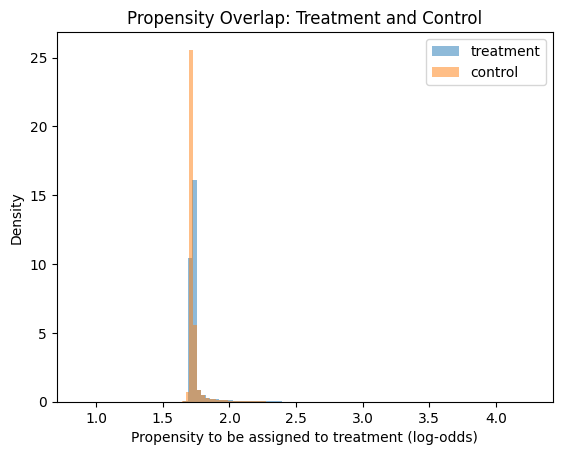

In [12]:
psm_data = data[feature_cols + ['treatment', 'conversion']].copy()

p = np.clip(propensity_all, 0.01, 0.99)
psm_data['propensity'] = p
psm_data['logit'] = np.log(p / (1 - p))

treated = psm_data[psm_data['treatment'] == 1]
control = psm_data[psm_data['treatment'] == 0]

plt.hist(treated['logit'], bins=100, density=True, alpha=0.5, label='treatment')
plt.hist(control['logit'], bins=100, density=True, alpha=0.5, label='control')
plt.xlabel('Propensity to be assigned to treatment (log-odds)')
plt.ylabel('Density')
plt.title('Propensity Overlap: Treatment and Control')
plt.legend()
plt.show()

**Result:**

- **Treatment AUC = 0.510**, which is very close to 0.5. So the features can barely predict who was put in the treatment group, which means the randomization mostly worked. With 14 million customers even a very small link between the features and treatment shows up, so it isn't exactly 0.5.
- The propensities are all very close to 0.85 (std = 0.009, and 50% of customers are between 0.846 and 0.849).
- In the plot, the treatment and control distributions sit almost on top of each other (control is a tiny bit to the left), so there is full overlap and every control customer should be able to find a match.
- **Conversion AUC = 0.959**, so the features predict conversion very well. This is useful for Double ML, because taking out the predictable part of conversion removes a lot of noise.

### Propensity Score Matching

- For each **control** customer, I find the treated customer with the closest propensity (1 nearest neighbor, on the log-odds scale). I match in this direction because there are about 6 treated customers for every control customer.
- Matching is **with replacement**, so one treated customer can be matched to more than one control customer.
- **Caliper:** if the closest match is more than 0.2 standard deviations of the log-odds away, I drop that control customer.
- **Ties:** a lot of customers have exactly the same propensity, so they would all be matched to the same treated customer. To avoid this, I add a tiny random number to each log-odds value so ties are broken at random.

In [13]:
caliper = 0.2 * psm_data['logit'].std()

# tiny random noise (much smaller than the caliper) to break ties
rng = np.random.default_rng(42)
treated_logit = treated[['logit']].to_numpy() + rng.uniform(-1e-6, 1e-6, size=(len(treated), 1))
control_logit = control[['logit']].to_numpy() + rng.uniform(-1e-6, 1e-6, size=(len(control), 1))

nn = NearestNeighbors(n_neighbors=1)
nn.fit(treated_logit)

distance, index = nn.kneighbors(control_logit)
distance = distance[:, 0]
index = index[:, 0]

keep = distance <= caliper

matched_control = control[keep]
matched_treated = treated.iloc[index[keep]]

# how many times each treated customer was used
times_used = matched_treated.index.value_counts()

print('Control customers:', len(control))
print('Share matched within the caliper:', keep.mean())
print('Different treated customers used:', len(times_used))
print('Most times one treated customer was used:', times_used.max())

Control customers: 2096937
Share matched within the caliper: 1.0
Different treated customers used: 1848041
Most times one treated customer was used: 7


**Balance after matching**

- I check the standardized mean differences (SMD) between treatment and control before and after matching. Below 0.1 is usually considered balanced.
- The SMDs were already small before matching because the experiment is randomized. So I also check two harder things: the SMD of the **predicted conversion probability**, and the share of each group in the top 10% of predicted conversion.

In [14]:
psm_data['outcome_prediction'] = y_pred_all

cutoff = psm_data['outcome_prediction'].quantile(0.9)
psm_data['top_10'] = (psm_data['outcome_prediction'] >= cutoff).astype(int)

cols = feature_cols + ['outcome_prediction']

matched = pd.concat([psm_data.loc[matched_treated.index], psm_data.loc[matched_control.index]])

balance = pd.DataFrame({
    'before matching': smd(psm_data, cols),
    'after matching': smd(matched, cols)
})

print('Largest absolute SMD before matching:', balance['before matching'].abs().max())
print('Largest absolute SMD after matching:', balance['after matching'].abs().max())
print()
print('Share in the top 10% by predicted conversion')
print('  Before matching: treatment', psm_data[psm_data['treatment'] == 1]['top_10'].mean(),
      '| control', psm_data[psm_data['treatment'] == 0]['top_10'].mean())
print('  After matching:  treatment', psm_data.loc[matched_treated.index, 'top_10'].mean(),
      '| control', psm_data.loc[matched_control.index, 'top_10'].mean())

balance.round(4)

Largest absolute SMD before matching: 0.04865965683047218
Largest absolute SMD after matching: 0.0039053178746567326

Share in the top 10% by predicted conversion
  Before matching: treatment 0.10155171550465784 | control 0.09120731810254672
  After matching:  treatment 0.09121256384908083 | control 0.09120731810254672


,before matching,after matching
f0,-0.0068,-0.0003
f1,0.0062,-0.0028
f2,-0.0046,-0.0005
f3,-0.0487,0.0017
f4,0.0042,-0.0035
f5,-0.0307,0.0025
f6,-0.0406,0.0003
f7,0.0205,-0.0012
f8,-0.0159,0.0006
f9,0.0244,-0.0012


**Result:**

- All 2,096,937 control customers found a match within the caliper (share matched = 1.0), so no one was dropped.
- 1,848,041 different treated customers were used, and no treated customer was used more than 7 times. So the matches aren't relying on just a few customers.
- **Feature balance:** the largest SMD went down from 0.049 (f3) before matching to 0.004 after matching. All features were already below 0.1 before matching, but matching made the groups even closer.
- **Top 10% by predicted conversion:** before matching, 10.2% of the treated group was in the top 10% vs 9.1% of the control group. So the treated group had slightly more customers who were likely to convert anyway. After matching it's 9.1% vs 9.1%, so this difference is gone.

### Average Effect: Three Estimates

1. **Raw difference:** treatment conversion rate minus control conversion rate. This relies on the randomization only. It is the effect of being targeted (ITT) that `Modeling_sample_2.ipynb` uses as its randomized comparison.
2. **Matched:** conversion rate of the matched treated customers minus their matched control customers.
3. **Double ML:** I take out the part of conversion and of treatment that the features can predict, and then regress what's left of conversion on what's left of treatment:

   `conversion − predicted conversion = effect × (treatment − propensity) + error`

   This is like partialling out controls in a regression (Frisch–Waugh–Lovell), but with Gradient Boosting. I use robust (HC1) standard errors.

- If the randomization worked, all three should be close. If treated customers were a bit more likely to convert anyway, the matched and Double ML estimates should be lower than the raw difference.
- The standard error of the matched estimate is only approximate. It accounts for treated customers being used more than once, but not for the propensity being estimated.

In [15]:
# 1. Raw difference
p_t = treated['conversion'].mean()
p_c = control['conversion'].mean()

raw_effect = p_t - p_c
raw_se = np.sqrt(p_t * (1 - p_t) / len(treated) + p_c * (1 - p_c) / len(control))

# 2. Matched
p_mt = matched_treated['conversion'].mean()
p_mc = matched_control['conversion'].mean()

matched_effect = p_mt - p_mc

# a treated customer used k times counts k times, so the SE has to be bigger
n_pairs = len(matched_control)
matched_se = np.sqrt(
    p_mc * (1 - p_mc) / n_pairs
    + p_mt * (1 - p_mt) * (times_used ** 2).sum() / n_pairs ** 2
)

# 3. Double ML
y_resid_all = y.to_numpy() - y_pred_all
t_resid_all = T.to_numpy() - np.clip(propensity_all, 0.01, 0.99)

dml = sm.OLS(y_resid_all, t_resid_all).fit(cov_type='HC1')

dml_effect = dml.params[0]
dml_se = dml.bse[0]

ate = pd.DataFrame({
    'effect': [raw_effect, matched_effect, dml_effect],
    'standard error': [raw_se, matched_se, dml_se]
}, index=['raw difference', 'matched', 'double ML'])

ate['lower 95%'] = ate['effect'] - 1.96 * ate['standard error']
ate['upper 95%'] = ate['effect'] + 1.96 * ate['standard error']

# in percentage points
(ate * 100).round(4)

,effect,standard error,lower 95%,upper 95%
raw difference,0.1152,0.0034,0.1085,0.1219
matched,0.0789,0.0051,0.0690,0.0888
double ML,0.0888,0.0032,0.0825,0.0951


**Result:**

- All three estimates are positive and none of the 95% intervals include 0, so being assigned to the campaign clearly increases conversion.
- **Raw difference:** 0.115 pp, 95% CI [0.109, 0.122], about a 59% relative lift
- **Matched:** 0.079 pp, 95% CI [0.069, 0.089], about a 41% relative lift
- **Double ML:** 0.089 pp, 95% CI [0.083, 0.095], about a 46% relative lift
- The relative lift is the effect divided by the control conversion rate (0.19%).
- The matched and Double ML estimates are **lower** than the raw difference, and now their intervals don't overlap with the raw difference interval. In the 5% sample the intervals overlapped, so I couldn't tell if this was real. With the full data it is: the raw difference gives the campaign about 0.03 pp too much credit, because the treated group had slightly more customers who would convert anyway (see the top 10% check above).
- This changes one point from `Modeling_sample_2.ipynb`. There I used the raw difference as the benchmark, because all treatment vs control SMDs were below 0.1. But with this many customers, even SMDs of about 0.05 are far larger than chance, and they are enough to shift the effect. So the adjusted estimates (matched and Double ML) are the better benchmark.
- The matched and Double ML intervals overlap, so they agree with each other.
- Double ML has the narrowest interval (SE = 0.003 pp) and the matched estimate the widest (SE = 0.005 pp). The intervals are about 5 times narrower than in the 5% sample, which is what I'd expect with 20 times more data.
- So my best estimate is that the campaign increases conversion by about **0.08 to 0.09 percentage points**, or roughly a **40-46% relative lift**. I use the Double ML estimate (0.089 pp) as my main number because it has the smallest interval.

### Double ML: Effect for Each Customer

- To rank customers, the effect has to depend on the features. So I keep the same idea as above, but let the effect be a **linear function of the features**:

  `conversion − predicted conversion = (a + b1 × f0 + ... + b12 × f11) × (treatment − propensity) + error`

- The predicted effect for a customer is then `a + b1 × f0 + ... + b12 × f11`.
- From here on I only train on the **training set**, like in `Modeling_sample_2.ipynb`. So I redo the cross-fitting on the training set only.
- I standardize the features with the training means and standard deviations, so the coefficients can be compared. Each coefficient is the change in the effect for a 1 std increase in that feature.

In [16]:
start = time.time()

y_pred_train, propensity_train = cross_fit(X_train, T_train, y_train)

y_resid = y_train.to_numpy() - y_pred_train
t_resid = T_train.to_numpy() - np.clip(propensity_train, 0.01, 0.99)

print('Minutes:', round((time.time() - start) / 60, 1))

Minutes: 19.7


In [17]:
train_mean = X_train.mean()
train_std = X_train.std()


def make_regressors(X):
    # a constant plus the standardized features
    X_std = (X - train_mean) / train_std
    return sm.add_constant(X_std, has_constant='add')


# multiply each regressor by the treatment residual
X_dml = make_regressors(X_train).mul(t_resid, axis=0)

dml_linear = sm.OLS(y_resid, X_dml).fit(cov_type='HC1')

coefs = pd.DataFrame({
    'coefficient': dml_linear.params,
    'lower 95%': dml_linear.conf_int()[0],
    'upper 95%': dml_linear.conf_int()[1],
    'p-value': dml_linear.pvalues
})

# coefficients in percentage points
coefs[['coefficient', 'lower 95%', 'upper 95%']] = coefs[['coefficient', 'lower 95%', 'upper 95%']] * 100
coefs.round(4)

,coefficient,lower 95%,upper 95%,p-value
const,0.0956,0.0870,0.1042,0.0000
f0,0.0063,-0.0068,0.0195,0.3450
f1,0.0063,-0.0528,0.0653,0.8354
f2,-0.0020,-0.0199,0.0159,0.8271
f3,-0.0961,-0.1205,-0.0717,0.0000
f4,0.3696,0.2566,0.4827,0.0000
f5,-0.0717,-0.1339,-0.0095,0.0239
f6,-0.0209,-0.0349,-0.0069,0.0034
f7,-0.0341,-0.0798,0.0116,0.1436
f8,0.0087,-0.0219,0.0392,0.5781


In [18]:
val_results['dml_linear'] = make_regressors(X_val).to_numpy() @ dml_linear.params.to_numpy()
results['dml_linear'] = make_regressors(X_test).to_numpy() @ dml_linear.params.to_numpy()

results['dml_linear'].describe()

count    2.795919e+06
mean     9.554968e-04
std      4.644622e-03
min     -8.800934e-04
25%     -3.226237e-04
50%     -1.623574e-04
75%      4.206264e-04
max      1.601228e-01
Name: dml_linear, dtype: float64

**Result:**

- **Constant = 0.096 pp:** this is the predicted effect for a customer with average feature values. It's close to the average effect from the cell above (0.089 pp).
- **7 of the 12 features are significant at the 5% level:**
  - **f4 (+0.37 pp)** and **f9 (+0.085 pp):** customers with higher values respond more to the campaign.
  - **f10 (-0.16 pp), f11 (-0.10 pp), f3 (-0.096 pp), f5 (-0.072 pp)** and **f6 (-0.021 pp):** customers with higher values respond less.
  - The strongest ones (p < 0.001) are f3, f4, f9 and f10.
- I would expect about 0.6 features to be significant just by chance, so this time there is **real evidence that the effect is different for different customers**. In the 5% sample only f3 and f4 were (just) significant, and they have the same direction here.
- **Predictions on the test set:** the mean predicted effect is 0.096 pp, but the median is -0.016 pp and the max is 16.0 pp. So more than half of the customers get a slightly negative prediction, and a few get very large ones.
- Like in the sample, this suggests the effect is concentrated in a small group of customers. I check in Extra 3 whether the negative predictions are real.

### Causal Forest

- A causal forest is like a random forest, but the trees look for groups of customers with **different treatment effects** instead of different outcomes. It doesn't assume the effect is linear.
- It uses the same residuals as Double ML (from the training set), so I reuse them.
- The trees are **honest**: each tree uses half of its customers to choose the splits and the other half to estimate the effect in each leaf. This is what makes confidence intervals possible.
- Each tree is built on 5% of the training customers (about 420,000). In the 5% sample I used 25%, but with the full data that would be about 2.1 million customers per tree and would take hours.
- **Tuning:** conversions are rare, so a leaf needs a lot of customers. I try 3 values of `min_samples_leaf` and pick the one with the highest Qini AUC on the validation set.
- This is the slowest part of the notebook, so I print the time for each forest.

In [19]:
forests = {}
tuning = []

for leaf_size in [500, 2000, 5000]:
    start = time.time()

    forest = CausalForest(
        n_estimators=200,
        min_samples_leaf=leaf_size,
        max_samples=0.05,      # 5% of the training customers per tree
        honest=True,
        inference=True,        # needed for the confidence intervals
        n_jobs=-1,
        random_state=42
    )
    forest.fit(X_train.to_numpy(), t_resid, y_resid)
    forests[leaf_size] = forest

    val_results['causal_forest'] = forest.predict(X_val.to_numpy()).ravel()
    qini = evaluate_model(val_results, 'causal_forest')['qini_auc']

    tuning.append({
        'min_samples_leaf': leaf_size,
        'validation_qini_auc': qini,
        'minutes': round((time.time() - start) / 60, 1)
    })

tuning = pd.DataFrame(tuning).sort_values('validation_qini_auc', ascending=False)

best_leaf = int(tuning.iloc[0]['min_samples_leaf'])
causal_forest = forests[best_leaf]

print('min_samples_leaf used:', best_leaf)
tuning

min_samples_leaf used: 5000


,min_samples_leaf,validation_qini_auc,minutes
2,5000,0.000381,11.7
1,2000,0.000379,13.4
0,500,0.000371,16.1


In [20]:
cf_effect, cf_lower, cf_upper = causal_forest.predict(X_test.to_numpy(), interval=True, alpha=0.05)

results['causal_forest'] = cf_effect.ravel()

print('Share of test customers whose 95% interval is entirely above 0:', (cf_lower.ravel() > 0).mean())
print('Share of test customers whose 95% interval is entirely below 0:', (cf_upper.ravel() < 0).mean())

results['causal_forest'].describe()

Share of test customers whose 95% interval is entirely above 0: 0.25330061421664934
Share of test customers whose 95% interval is entirely below 0: 0.0


count    2.795919e+06
mean     9.218854e-04
std      2.443632e-03
min     -5.292072e-05
25%      3.432065e-05
50%      9.628919e-05
75%      4.520108e-04
max      1.805787e-02
Name: causal_forest, dtype: float64

- **Feature importance:** this shows which features the forest uses most for its splits (splits near the top of the trees count more). It shows which features the model **uses** to separate customers with different effects, not which features cause customers to respond.

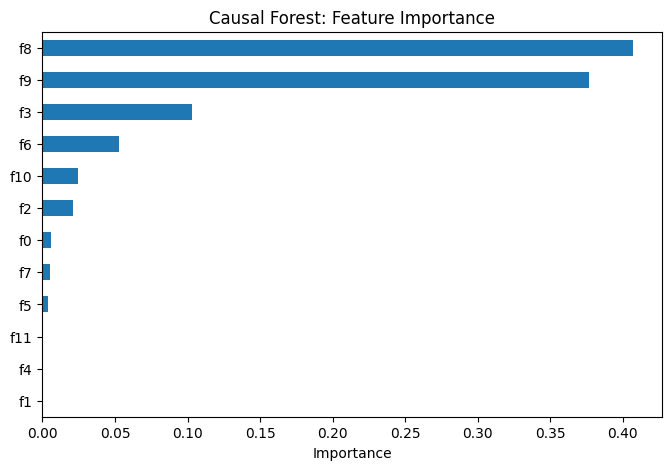

In [21]:
importance = pd.Series(causal_forest.feature_importances_, index=feature_cols).sort_values()

importance.plot.barh(figsize=(8, 5))
plt.xlabel('Importance')
plt.title('Causal Forest: Feature Importance')
plt.show()

**Result:**

- **Tuning:** this time `min_samples_leaf = 5000` had the best validation Qini AUC (0.000381 vs 0.000379 for 2000 and 0.000371 for 500). In the 5% sample the smallest leaf size was best. The differences are tiny again, but with the full data bigger leaves seem to work a bit better, probably because they average out more noise. Even bigger leaves might be worth trying.
- **Predictions on the test set:** the mean predicted effect is 0.092 pp, very close to the Double ML average effect (0.089 pp). The median is only 0.010 pp and the max is 1.8 pp. So the forest also says most customers barely respond and a small group responds a lot.
- The forest's predictions are much less extreme than the linear Double ML ones (std 0.24 pp vs 0.46 pp), and almost none are negative (the min is -0.005 pp).
- **Confidence intervals:** 25.3% of test customers have an interval entirely above 0, so the forest is fairly confident they respond positively. No customers have an interval entirely below 0, so there's no evidence that the campaign hurts anyone. (Each customer's interval is checked separately, so these shares are only a rough guide.)
- **Feature importance:** f8 (approx. 0.41) and f9 (approx. 0.38) are by far the most used features, followed by f3 (approx. 0.10) and f6 (approx. 0.05). f10 and f2 are used a little, and f4, f1 and f11 are almost never used.
- This partly agrees with Double ML: f3, f6 and f9 were significant there too. But there are two differences:
  - **f8** is the forest's top feature but wasn't significant in Double ML. So its effect is probably not a straight line, which the linear model can't capture.
  - **f4** had the biggest Double ML coefficient, but the forest barely uses it. One possible reason is that the forest finds the same customers through f8 and f9, or that a few extreme f4 values are pulling the linear model (its max prediction was 16 pp).
- f8 being the main driver matches what a 2026 paper on the same dataset found.

### Comparing the Models on the Test Set

- First a quick check: I compare the average predicted effect of each model with the actual average effect in the test set, and look at the range of the predictions.

In [22]:
model_cols = ['baseline', 'dml_linear', 'causal_forest']

test_treated = results[results['treatment'] == 1]['conversion'].mean()
test_control = results[results['treatment'] == 0]['conversion'].mean()

print('Observed average effect in the test set:', test_treated - test_control)

results[['dml_linear', 'causal_forest']].describe().T[['mean', 'std', 'min', '50%', 'max']]

Observed average effect in the test set: 0.0011508378971446258


,mean,std,min,50%,max
dml_linear,0.000955,0.004645,-0.000880,-0.000162,0.160123
causal_forest,0.000922,0.002444,-0.000053,0.000096,0.018058


- Next, the metrics with 95% bootstrap confidence intervals, and then the difference from the baseline. If the interval for the difference includes 0, the model isn't clearly different from the baseline.

In [23]:
start = time.time()

boot = bootstrap(results, model_cols)

print('Minutes:', round((time.time() - start) / 60, 1))

ci_table(results, model_cols, boot)

Minutes: 10.5


,qini_auc,uplift@5%,uplift@10%,uplift@20%,uplift@30%,uplift@50%
baseline,"0.0004 [0.0003, 0.0005]","0.0135 [0.0106, 0.0163]","0.0082 [0.0067, 0.0097]","0.0048 [0.0040, 0.0056]","0.0035 [0.0031, 0.0040]","0.0022 [0.0020, 0.0025]"
dml_linear,"0.0004 [0.0003, 0.0004]","0.0132 [0.0103, 0.0160]","0.0080 [0.0066, 0.0095]","0.0046 [0.0038, 0.0053]","0.0034 [0.0029, 0.0039]","0.0021 [0.0019, 0.0024]"
causal_forest,"0.0004 [0.0003, 0.0005]","0.0129 [0.0101, 0.0155]","0.0084 [0.0070, 0.0098]","0.0049 [0.0042, 0.0057]","0.0035 [0.0030, 0.0040]","0.0022 [0.0019, 0.0025]"


In [24]:
diff_table(results, model_cols, boot)

,qini_auc,uplift@5%,uplift@10%,uplift@20%,uplift@30%,uplift@50%
dml_linear,"-0.0000 [-0.0000, -0.0000]","-0.0003 [-0.0013, 0.0006]","-0.0002 [-0.0006, 0.0003]","-0.0002 [-0.0003, -0.0000]","-0.0001 [-0.0002, -0.0001]","-0.0001 [-0.0001, -0.0000]"
causal_forest,"-0.0000 [-0.0000, 0.0000]","-0.0005 [-0.0019, 0.0007]","0.0001 [-0.0003, 0.0006]","0.0001 [-0.0000, 0.0003]","-0.0000 [-0.0001, 0.0000]","-0.0000 [-0.0001, 0.0000]"


C:\Users\parva\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


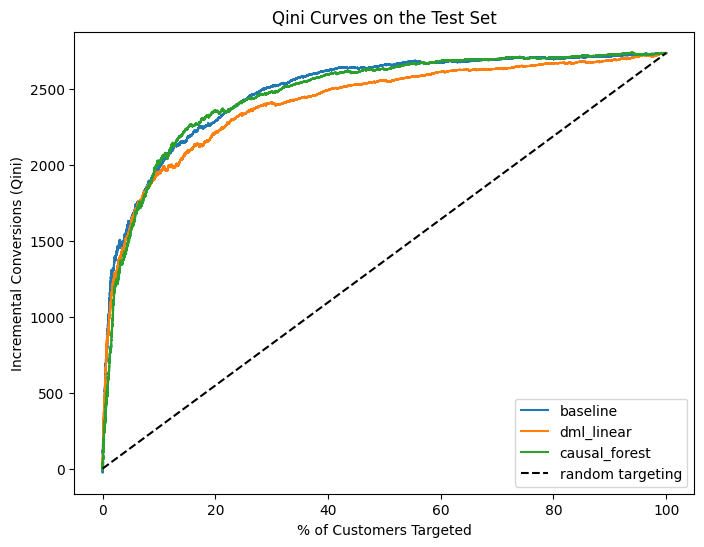

In [25]:
plt.figure(figsize=(8, 6))

for col in model_cols:
    curve = uplift_curve(results, col)
    plt.plot(curve['pct_targeted'] * 100, curve['qini'], label=col)

# random targeting line
last_qini = uplift_curve(results, 'baseline')['qini'].iloc[-1]
plt.plot([0, 100], [0, last_qini], 'k--', label='random targeting')

plt.xlabel('% of Customers Targeted')
plt.ylabel('Incremental Conversions (Qini)')
plt.title('Qini Curves on the Test Set')
plt.legend()
plt.show()

**Result:**

**Sanity check**

- The observed average effect in the test set is 0.115 pp. Double ML (0.096 pp) and the causal forest (0.092 pp) are a bit lower, which fits with the adjusted average effects (0.08-0.09 pp) being lower than the raw difference.
- Both models give realistic predictions (between -0.09 pp and +16.0 pp). For comparison, the T-learner in `Modeling_fulldata.ipynb` predicts effects from -84.7 pp to +79.5 pp, because even with the full data its control model only has 2,438 conversions to learn from.

**Metrics**

- With the full data, all the intervals are much narrower than in the 5% sample, and all of them are above 0.
- **Qini AUC:** the baseline, the causal forest and Double ML are all about 0.0004.
- **Top 10%:** the causal forest has 0.84 pp, the baseline 0.82 pp and Double ML 0.80 pp. That's about **7 times** the average effect.
- **Top 50%:** all three models have an uplift of about 0.22 pp, about **twice** the average effect (0.115 pp).

**Difference from the baseline**

- **Causal forest:** all the intervals include 0, so even with 14 million customers it is **not clearly better or worse than the baseline**.
- **Double ML:** clearly **worse** than the baseline on Qini AUC and in the top 20%, 30% and 50%, but the differences are small (0.01-0.02 pp).
- So the order is: baseline ≈ causal forest > Double ML.

**Qini curves**

- All the models are well above the random targeting line. There are about 2,700 incremental conversions in total.
- The baseline and the causal forest are almost on top of each other, and they cross a few times.
- Double ML is a bit below them from about 10% to 90%.
- With the baseline or the causal forest, the top 10% of customers give about 2,000 of the ~2,700 incremental conversions (about 75%), and the top 20% about 85%. After 40% almost nothing is added.

**Overall**

- With 20 times more data, the conclusions are the same as in the 5% sample, but now they're much more certain: the causal forest ties the baseline, and Double ML is worse. In the extra sections below I look at why.

### Extra 1: Effect of Actually Seeing the Ad

- Everything above is the effect of being **assigned** to the campaign. But not everyone in the treatment group actually saw the ad.
- No one in the control group could see the ad. So the whole effect of assignment comes from the treated customers who saw it.
- That means I can get the effect of **seeing** the ad by dividing the effect of assignment by the share of the treatment group that saw it:

  `effect of seeing the ad = effect of assignment / share of treatment group that saw the ad`

- This is the instrumental variable (Wald) estimate, with random assignment as the instrument. It assumes that being assigned only changes conversion through seeing the ad.
- It's the effect for the customers who saw the ad, not for everyone.
- I don't compare customers who saw the ad with customers who didn't, because the ones who saw it were probably different to begin with (for example, more active online). `Modeling_sample_2.ipynb` checks this directly: the features predict exposure with an AUC of 0.92, and matching on them still overstates the effect.
- This is the same calculation as the randomized comparison in `Modeling_sample_2.ipynb` (ITT / exposure rate). Here I also apply it to the matched and Double ML estimates.

In [26]:
# I didn't load exposure at the start, so I load it now
exposure = pd.read_parquet('uplift_clean.parquet', columns=['exposure'])['exposure']

pd.crosstab(T, exposure)

exposure,0,1
treatment,,
0,2096937,0
1,11454443,428212


In [27]:
share_treated = exposure[T == 1].mean()
share_control = exposure[T == 0].mean()
share_exposed = share_treated - share_control

print('Share of the treatment group that saw the ad:', share_treated)
print('Share of the control group that saw the ad:', share_control)
print()

# the wrong comparison, just to show why I don't use it
print('Conversion rate, treated and saw the ad:', y[(T == 1) & (exposure == 1)].mean())
print('Conversion rate, treated and did not see the ad:', y[(T == 1) & (exposure == 0)].mean())
print('Conversion rate, control:', y[T == 0].mean())

# divide all three average effects by the share that saw the ad
# (the share is estimated very precisely, so I ignore its uncertainty)
effect_if_seen = ate[['effect', 'lower 95%', 'upper 95%']] / share_exposed

# in percentage points
(effect_if_seen * 100).round(3)

Share of the treatment group that saw the ad: 0.036036727482199896
Share of the control group that saw the ad: 0.0

Conversion rate, treated and saw the ad: 0.053784106937685074
Conversion rate, treated and did not see the ad: 0.0011942963966034839
Conversion rate, control: 0.0019375880152813366


,effect,lower 95%,upper 95%
raw difference,3.196,3.009,3.383
matched,2.189,1.913,2.464
double ML,2.465,2.291,2.639


In [28]:
# add exposure to the test set results for the next sections
results['exposure'] = exposure.loc[X_test.index].to_numpy()

**Result:**

- Only **3.6%** of the treatment group saw the ad, and none of the control group did.
- **Effect of seeing the ad:** 2.47 pp with Double ML (95% CI [2.29, 2.64]). The raw difference gives 3.20 pp and matching gives 2.19 pp. That's about **28 times** the effect of being assigned.
- In `Modeling_sample_2.ipynb` the raw difference gave 3.13 pp on the 5% sample, close to the 3.20 pp here. The adjusted estimate (2.47 pp) is lower, so the matched estimate on exposure in that notebook (4.89 pp) overstated the effect by even more than it looked there.
- The treated customers who saw the ad converted 5.38% of the time. Without the ad they would have converted about 2.9% of the time (5.38% - 2.47 pp). So for the customers who saw it, the ad almost doubles conversion (about an 85% lift).
- That 2.9% is still about **15 times** the control conversion rate (0.19%). So the customers who are shown the ad were already much more likely to convert than average.
- This is also why comparing customers who saw the ad with those who didn't would be wrong: the treated customers who didn't see the ad converted only 0.12% of the time, even less than the control group. Comparing 5.38% with 0.12% would make the ad look more than twice as effective as it is.
- This estimate assumes that being assigned only changes conversion through seeing the ad.

### Extra 2: Why Is the Baseline So Hard to Beat?

- The baseline only predicts how likely a customer is to convert if treated. It doesn't look at the control group at all, but it did as well as the causal forest.
- To see why, I split the test set into 10 groups (deciles) by the baseline score and look at the **observed** uplift in each group. Decile 1 is the 10% with the highest score.
- I also look at the share of treated customers who **saw the ad** in each decile. If the customers who are likely to convert are also the ones who get shown the ad, that alone would make their uplift bigger.
- `uplift if seen` is the uplift divided by the share that saw the ad (same idea as in Extra 1).

In [29]:
def group_uplift(group):
    # observed uplift in a group of customers, with its standard error
    tr = group[group['treatment'] == 1]['conversion']
    co = group[group['treatment'] == 0]['conversion']
    uplift = tr.mean() - co.mean()
    se = np.sqrt(tr.var() / len(tr) + co.var() / len(co))
    return uplift, se


def uplift_by_decile(df, score_col):
    # decile 1 = the 10% with the highest score
    decile = 10 - pd.qcut(df[score_col].rank(method='first'), 10, labels=False)

    rows = []
    for d in range(1, 11):
        group = df[decile == d]
        uplift, se = group_uplift(group)
        seen = group[group['treatment'] == 1]['exposure'].mean()
        rows.append({
            'decile': d,
            'mean score': group[score_col].mean(),
            'uplift': uplift,
            'lower 95%': uplift - 1.96 * se,
            'upper 95%': uplift + 1.96 * se,
            'share saw ad (treated)': seen,
            'uplift if seen': uplift / seen
        })
    return pd.DataFrame(rows).set_index('decile')


by_baseline = uplift_by_decile(results, 'baseline')
by_forest = uplift_by_decile(results, 'causal_forest')

print('Rank correlation between baseline and causal forest scores:',
      results['baseline'].corr(results['causal_forest'], method='spearman'))

by_baseline.round(5)

Rank correlation between baseline and causal forest scores: 0.9150630425474371


,mean score,uplift,lower 95%,upper 95%,share saw ad (treated),uplift if seen
decile,,,,,,
1,0.02706,0.00822,0.00672,0.00973,0.19583,0.04200
2,0.00185,0.00051,0.00011,0.00091,0.06845,0.00747
3,0.00067,0.00044,0.00027,0.00061,0.02744,0.01599
4,0.00030,0.00014,0.00001,0.00027,0.01412,0.00987
5,0.00018,-0.00001,-0.00014,0.00012,0.01522,-0.00047
6,0.00012,0.00001,-0.00012,0.00013,0.02446,0.00023
7,0.00008,0.00005,-0.00003,0.00013,0.00490,0.01011
8,0.00007,-0.00003,-0.00011,0.00006,0.00222,-0.01301
9,0.00007,0.00008,0.00004,0.00011,0.00133,0.05714


In [30]:
by_forest.round(5)

,mean score,uplift,lower 95%,upper 95%,share saw ad (treated),uplift if seen
decile,,,,,,
1,0.00700,0.00835,0.00690,0.00981,0.17645,0.04733
2,0.00127,0.00098,0.00053,0.00144,0.08900,0.01104
3,0.00046,0.00012,-0.00017,0.00040,0.04076,0.00282
4,0.00020,0.00015,0.00001,0.00029,0.02487,0.00618
5,0.00012,-0.00002,-0.00017,0.00014,0.01182,-0.00155
6,0.00008,0.00013,0.00005,0.00021,0.00312,0.04177
7,0.00005,0.00003,-0.00002,0.00009,0.00279,0.01111
8,0.00003,0.00000,-0.00009,0.00009,0.00231,0.00031
9,0.00002,0.00006,0.00000,0.00012,0.00227,0.02850


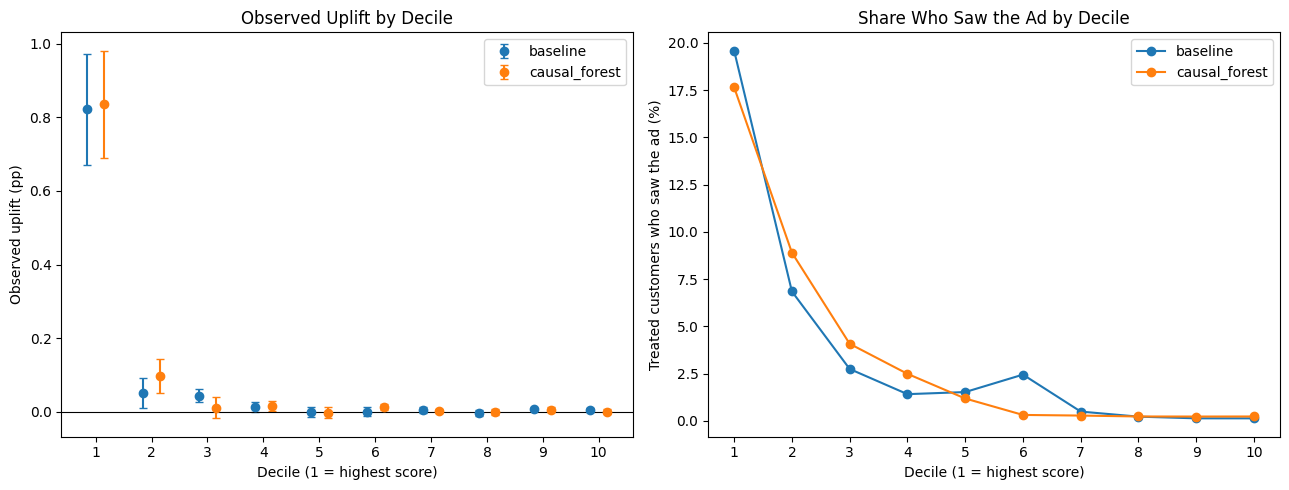

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, table, shift in [('baseline', by_baseline, -0.15), ('causal_forest', by_forest, 0.15)]:
    axes[0].errorbar(table.index + shift, table['uplift'] * 100,
                     yerr=[(table['uplift'] - table['lower 95%']) * 100, (table['upper 95%'] - table['uplift']) * 100],
                     fmt='o', capsize=3, label=name)
    axes[1].plot(table.index, table['share saw ad (treated)'] * 100, marker='o', label=name)

axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_xlabel('Decile (1 = highest score)')
axes[0].set_ylabel('Observed uplift (pp)')
axes[0].set_title('Observed Uplift by Decile')
axes[0].set_xticks(range(1, 11))
axes[0].legend()

axes[1].set_xlabel('Decile (1 = highest score)')
axes[1].set_ylabel('Treated customers who saw the ad (%)')
axes[1].set_title('Share Who Saw the Ad by Decile')
axes[1].set_xticks(range(1, 11))
axes[1].legend()

plt.tight_layout()
plt.show()

**Does the causal forest add anything on top of the baseline?**

- I split the test set into 5 groups (quintiles) by the baseline score. Inside each group, I split the customers in half by the causal forest score.
- If the causal forest knows something the baseline doesn't, the top half should have a higher uplift than the bottom half **inside the same baseline group**.
- I use quintiles instead of deciles so each half still has enough control conversions.

In [32]:
results['baseline_group'] = 5 - pd.qcut(results['baseline'].rank(method='first'), 5, labels=False)

rows = []
for g in range(1, 6):
    group = results[results['baseline_group'] == g]

    # split the group in half by the causal forest score
    forest_rank = group['causal_forest'].rank(method='first', pct=True)
    top = group[forest_rank > 0.5]
    bottom = group[forest_rank <= 0.5]

    top_uplift, top_se = group_uplift(top)
    bottom_uplift, bottom_se = group_uplift(bottom)

    rows.append({
        'baseline group': g,
        'top half uplift': top_uplift,
        'bottom half uplift': bottom_uplift,
        'difference': top_uplift - bottom_uplift,
        'difference se': np.sqrt(top_se ** 2 + bottom_se ** 2),
        'control conversions': group[group['treatment'] == 0]['conversion'].sum()
    })

within = pd.DataFrame(rows).set_index('baseline group')

# average difference over the 5 groups
avg_diff = within['difference'].mean()
avg_se = np.sqrt((within['difference se'] ** 2).sum()) / 5

print('Average difference (top half - bottom half):', round(avg_diff * 100, 3), 'pp')
print('95% CI:', round((avg_diff - 1.96 * avg_se) * 100, 3), 'to', round((avg_diff + 1.96 * avg_se) * 100, 3), 'pp')

# effects in percentage points
pp_cols = ['top half uplift', 'bottom half uplift', 'difference', 'difference se']
within[pp_cols] = within[pp_cols] * 100
within.round(3)

Average difference (top half - bottom half): 0.162 pp
95% CI: 0.131 to 0.194 pp


,top half uplift,bottom half uplift,difference,difference se,control conversions
baseline group,,,,,
1,0.838,0.067,0.771,0.079,779
2,0.045,0.013,0.033,0.011,15
3,0.000,-0.001,0.001,0.009,13
4,0.004,-0.002,0.005,0.006,5
5,0.007,0.005,0.002,0.003,1


**Combining the two scores**

- If the causal forest does add something, combining it with the baseline might beat both.
- I use a simple combination: the percentile rank of the baseline plus the percentile rank of the causal forest. I decided on equal weights before looking at the results, so I'm not tuning anything on the test set.
- I compare it with the baseline using the same bootstrap as before.

In [33]:
results['combined'] = results['baseline'].rank(pct=True) + results['causal_forest'].rank(pct=True)

combined_cols = ['baseline', 'causal_forest', 'combined']

start = time.time()
boot_combined = bootstrap(results, combined_cols)
print('Minutes:', round((time.time() - start) / 60, 1))

ci_table(results, combined_cols, boot_combined)

Minutes: 9.8


,qini_auc,uplift@5%,uplift@10%,uplift@20%,uplift@30%,uplift@50%
baseline,"0.0004 [0.0003, 0.0005]","0.0135 [0.0106, 0.0163]","0.0082 [0.0067, 0.0097]","0.0048 [0.0040, 0.0056]","0.0035 [0.0031, 0.0040]","0.0022 [0.0020, 0.0025]"
causal_forest,"0.0004 [0.0003, 0.0005]","0.0129 [0.0101, 0.0155]","0.0084 [0.0070, 0.0098]","0.0049 [0.0042, 0.0057]","0.0035 [0.0030, 0.0040]","0.0022 [0.0019, 0.0025]"
combined,"0.0004 [0.0003, 0.0005]","0.0133 [0.0104, 0.0162]","0.0084 [0.0070, 0.0099]","0.0048 [0.0041, 0.0056]","0.0035 [0.0030, 0.0040]","0.0022 [0.0020, 0.0025]"


In [34]:
diff_table(results, combined_cols, boot_combined)

,qini_auc,uplift@5%,uplift@10%,uplift@20%,uplift@30%,uplift@50%
causal_forest,"-0.0000 [-0.0000, 0.0000]","-0.0005 [-0.0019, 0.0007]","0.0001 [-0.0003, 0.0006]","0.0001 [-0.0000, 0.0003]","-0.0000 [-0.0001, 0.0000]","-0.0000 [-0.0001, 0.0000]"
combined,"-0.0000 [-0.0000, 0.0000]","-0.0002 [-0.0010, 0.0006]","0.0002 [-0.0001, 0.0005]","0.0000 [-0.0000, 0.0001]","-0.0000 [-0.0000, 0.0000]","0.0000 [-0.0000, 0.0000]"


**Result:**

**Uplift and seeing the ad by decile**

- The rank correlation between the baseline and the causal forest scores is **0.92**, so the two models put customers in almost the same order.
- **Baseline deciles:** the top decile has an uplift of 0.82 pp (95% CI [0.67, 0.97]), about 7 times the average effect. It has about **87% of all the incremental conversions** (adding up the uplift of all deciles; measured on the Qini curve it is about 75%, see the model comparison above). Deciles 2 and 3 have about 0.04-0.05 pp, and deciles 5-10 have almost none.
- The causal forest deciles look very similar. Its top decile has 0.84 pp, and its second decile is a bit better than the baseline's (0.10 pp vs 0.05 pp).
- **Who saw the ad:** in the baseline's top decile, 19.6% of treated customers saw the ad, more than 5 times the overall 3.6%. It drops to about 0.1% in deciles 9 and 10. So the customers who are likely to convert are also the ones who get shown the ad (the ad system probably targets them).
- **Uplift if seen:** in the top decile it's 4.2 pp, vs about 0.7-1.6 pp in deciles 2-4. So it's not only that the top decile sees the ad more often: these customers also respond more when they see it. (In deciles 5-10 so few customers saw the ad that these numbers are just noise.)
- So this explains why the baseline is hard to beat: almost all of the uplift is in the customers who are most likely to convert. They are more likely to see the ad **and** more likely to respond to it. So ranking customers by how likely they are to convert is almost the same as ranking them by uplift.

**Does the causal forest add anything on top of the baseline?**

- The average difference between the top and bottom half is 0.16 pp (95% CI [0.13, 0.19]), so at first it looks like the forest adds something.
- But almost all of it comes from the top baseline group (0.77 pp difference), which has 779 of the 813 control conversions. Groups 3-5 have too few control conversions (1-13) to say anything.
- The baseline itself would split these groups just as well. The top baseline group is baseline deciles 1 and 2, and their uplifts (0.82 vs 0.05 pp) also differ by **0.77 pp**, the same as the forest's split. For group 2 (baseline deciles 3 and 4) it's 0.030 pp for the baseline vs 0.033 pp for the forest.
- So inside each baseline group, the forest separates customers about as well as the baseline does, not better.

**Combining the two scores**

- The combined score ties the baseline on every metric (all intervals include 0). The biggest difference is in the top 10% (+0.02 pp, CI [-0.01, 0.05]).
- So on this data the causal forest doesn't add useful information on top of the baseline.

### Extra 3: Are the Predicted Effects the Right Size?

- Qini AUC only checks if the **order** of the customers is right. If someone wants to use the predicted effects to plan a budget, the **size** also has to be right.
- For Double ML and the causal forest, I compare the average predicted effect in each decile with the observed uplift in that decile. If the predictions are right, the points should be close to the diagonal line.
- I also check the customers whose causal forest interval was entirely above 0. If the forest is right about them, their observed uplift should be clearly above 0.

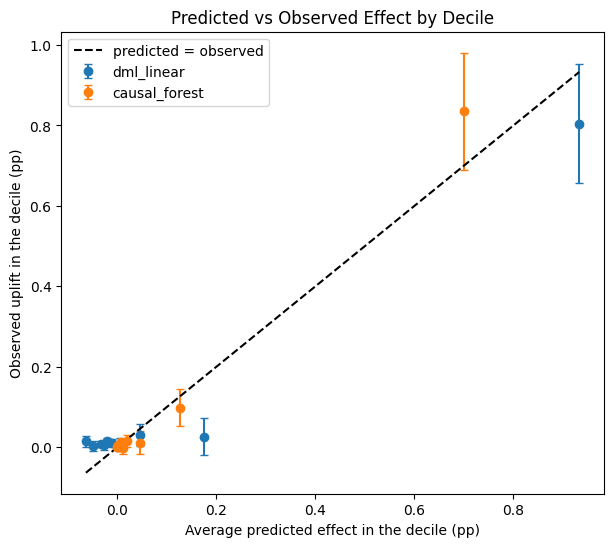

,mean score,uplift,lower 95%,upper 95%
decile,,,,
1,0.00933,0.00805,0.00657,0.00953
2,0.00175,0.00026,-0.00020,0.00072
3,0.00046,0.00030,0.00002,0.00057
4,0.00005,0.00006,-0.00009,0.00022
5,-0.00010,0.00011,0.00001,0.00021
6,-0.00020,0.00015,0.00008,0.00022
7,-0.00027,0.00004,-0.00006,0.00015
8,-0.00032,0.00008,0.00000,0.00016
9,-0.00050,0.00003,-0.00011,0.00016


In [35]:
by_dml = uplift_by_decile(results, 'dml_linear')

plt.figure(figsize=(7, 6))

for name, table in [('dml_linear', by_dml), ('causal_forest', by_forest)]:
    plt.errorbar(table['mean score'] * 100, table['uplift'] * 100,
                 yerr=[(table['uplift'] - table['lower 95%']) * 100, (table['upper 95%'] - table['uplift']) * 100],
                 fmt='o', capsize=3, label=name)

# diagonal line = predicted equals observed
low = min(by_dml['mean score'].min(), by_forest['mean score'].min()) * 100
high = max(by_dml['mean score'].max(), by_forest['mean score'].max()) * 100
plt.plot([low, high], [low, high], 'k--', label='predicted = observed')

plt.xlabel('Average predicted effect in the decile (pp)')
plt.ylabel('Observed uplift in the decile (pp)')
plt.title('Predicted vs Observed Effect by Decile')
plt.legend()
plt.show()

by_dml[['mean score', 'uplift', 'lower 95%', 'upper 95%']].round(5)

In [36]:
results['cf_confident'] = cf_lower.ravel() > 0

rows = []
for name, group in [('interval above 0', results[results['cf_confident']]),
                    ('everyone else', results[~results['cf_confident']])]:
    uplift, se = group_uplift(group)
    rows.append({
        'group': name,
        'customers': len(group),
        'average predicted effect': group['causal_forest'].mean(),
        'observed uplift': uplift,
        'lower 95%': uplift - 1.96 * se,
        'upper 95%': uplift + 1.96 * se
    })

confident = pd.DataFrame(rows).set_index('group')

# effects in percentage points
confident[['average predicted effect', 'observed uplift', 'lower 95%', 'upper 95%']] *= 100
confident.round(3)

,customers,average predicted effect,observed uplift,lower 95%,upper 95%
group,,,,,
interval above 0,708208,0.325,0.400,0.341,0.459
everyone else,2087711,0.013,0.007,0.001,0.012


**Result:**

- **Causal forest:** the points are close to the diagonal line.
  - Top decile: predicted 0.70 pp vs observed 0.84 pp (CI [0.69, 0.98]).
  - Second decile: predicted 0.13 pp vs observed 0.10 pp (CI [0.05, 0.14]).
  - In the other deciles both are close to 0.
  - So the forest's effect sizes are about right, and if anything a little cautious for the top customers.
- **Double ML:**
  - The top decile is fine: predicted 0.93 pp vs observed 0.80 pp (CI [0.66, 0.95]).
  - The second decile is predicted at 0.18 pp but the observed uplift is only 0.03 pp (CI [-0.02, 0.07]), so it over-predicts there.
  - Deciles 5-10 get negative predictions (down to -0.06 pp), but their observed uplift is slightly positive (for example decile 10: predicted -0.064 pp, observed +0.014 pp, CI [0.000, 0.028]).
  - So the negative predictions are **not real**, like I suspected. They come from the linear model, not from the data.
- **Customers whose forest interval was above 0:** there are 708,208 of them (25%). Their predicted effect was 0.33 pp and their observed uplift is 0.40 pp (CI [0.34, 0.46]). Everyone else had a predicted 0.013 pp and an observed 0.007 pp.
- So the forest is right about these customers. They account for about **95%** of the incremental conversions (uplift × number of customers), even though they're only a quarter of the customers.
- Another project on this dataset found its predicted gains were much too optimistic. Here the forest's predictions are not too optimistic, so they could be used for planning a budget, not just for ranking.

### Extra 4: How Much Data Do the Causal Models Need?

- With the 5% sample, none of the causal models was clearly better than the baseline. Here I check if that changes with more data.
- I train the baseline, Double ML and the causal forest on 1%, 5% and 25% of the training set, and reuse the 100% results from above.
- I always evaluate on the **full test set**, so only the amount of training data changes.
- For the causal forest I use the `min_samples_leaf` picked above. Each tree uses 25% of the training customers, but at most 420,000, like in the main analysis.
- For each size I look at the difference from the baseline (Qini AUC and uplift in the top 10%), with the same bootstrap intervals as before.
- This takes a while, because each size needs its own cross-fitting, forest and bootstrap.

In [37]:
def difference_rows(df, cols, boot, metrics):
    # difference from the baseline, as numbers (diff_table gives text)
    base = evaluate_model(df, 'baseline')
    rows = []
    for col in cols:
        if col == 'baseline':
            continue
        est = evaluate_model(df, col)
        for m in metrics:
            d = boot[col][m] - boot['baseline'][m]
            rows.append({
                'model': col,
                'metric': m,
                'difference': est[m] - base[m],
                'lower 95%': d.quantile(0.025),
                'upper 95%': d.quantile(0.975)
            })
    return rows


size_cols = ['baseline', 'dml_linear', 'causal_forest']
size_metrics = ['qini_auc', 'uplift@10%']
size_rows = []

for frac in [0.01, 0.05, 0.25, 1.0]:
    start = time.time()

    if frac == 1.0:
        # already done above
        n_train = len(X_train)
        control_conv = y_train[T_train == 0].sum()
        size_df = results[['treatment', 'conversion'] + size_cols]
        size_boot = boot

    else:
        # stratified subset of the training set
        X_sub, _, T_sub, _, y_sub, _ = train_test_split(
            X_train, T_train, y_train,
            train_size=frac,
            random_state=42,
            stratify=T_train * 2 + y_train
        )
        n_train = len(X_sub)
        control_conv = y_sub[T_sub == 0].sum()

        # baseline
        gb_sub = train_gb(X_sub[T_sub == 1], y_sub[T_sub == 1])

        # residuals for Double ML and the causal forest
        y_pred_sub, propensity_sub = cross_fit(X_sub, T_sub, y_sub)
        y_resid_sub = y_sub.to_numpy() - y_pred_sub
        t_resid_sub = T_sub.to_numpy() - np.clip(propensity_sub, 0.01, 0.99)

        # Double ML (linear)
        dml_sub = sm.OLS(y_resid_sub, make_regressors(X_sub).mul(t_resid_sub, axis=0)).fit()

        # causal forest
        forest_sub = CausalForest(
            n_estimators=200,
            min_samples_leaf=best_leaf,
            max_samples=min(0.25, 420000 / n_train),
            honest=True,
            inference=True,
            n_jobs=-1,
            random_state=42
        )
        forest_sub.fit(X_sub.to_numpy(), t_resid_sub, y_resid_sub)

        # scores on the full test set
        size_df = results[['treatment', 'conversion']].copy()
        size_df['baseline'] = gb_sub.predict_proba(X_test)[:, 1]
        size_df['dml_linear'] = make_regressors(X_test).to_numpy() @ dml_sub.params.to_numpy()
        size_df['causal_forest'] = forest_sub.predict(X_test.to_numpy()).ravel()

        size_boot = bootstrap(size_df, size_cols)

    for row in difference_rows(size_df, size_cols, size_boot, size_metrics):
        row['train share'] = frac
        row['train customers'] = n_train
        row['control conversions in train'] = control_conv
        size_rows.append(row)

    print(f'{frac:.0%} of the training set done, minutes:', round((time.time() - start) / 60, 1))

size_results = pd.DataFrame(size_rows)
size_results

1% of the training set done, minutes: 9.9
5% of the training set done, minutes: 12.6
25% of the training set done, minutes: 25.2
100% of the training set done, minutes: 0.1


,model,metric,difference,lower 95%,upper 95%,train share,train customers,control conversions in train
0,dml_linear,qini_auc,-0.000167,-0.000220,-1.160354e-04,0.01,83877,25
1,dml_linear,uplift@10%,-0.001317,-0.002084,-5.654754e-04,0.01,83877,25
2,causal_forest,qini_auc,-0.000054,-0.000086,-2.010617e-05,0.01,83877,25
3,causal_forest,uplift@10%,-0.001008,-0.001984,-1.223351e-04,0.01,83877,25
4,dml_linear,qini_auc,-0.000039,-0.000055,-2.066585e-05,0.05,419387,122
5,dml_linear,uplift@10%,-0.000099,-0.000571,3.255648e-04,0.05,419387,122
6,causal_forest,qini_auc,-0.000009,-0.000019,9.928050e-07,0.05,419387,122
7,causal_forest,uplift@10%,0.000148,-0.000419,7.149337e-04,0.05,419387,122
8,dml_linear,qini_auc,-0.000030,-0.000044,-1.399339e-05,0.25,2096938,609
9,dml_linear,uplift@10%,-0.000205,-0.000646,1.951464e-04,0.25,2096938,609


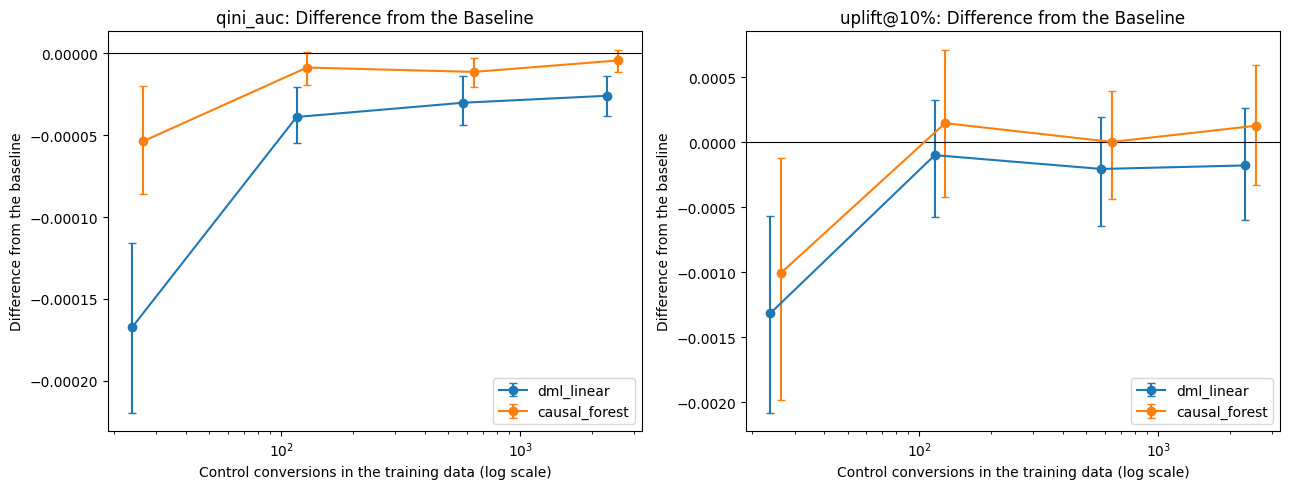

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, m in zip(axes, size_metrics):
    for col, shift in [('dml_linear', 0.95), ('causal_forest', 1.05)]:
        part = size_results[(size_results['model'] == col) & (size_results['metric'] == m)]
        x = part['control conversions in train'] * shift   # small shift so the bars don't overlap
        ax.errorbar(x, part['difference'],
                    yerr=[part['difference'] - part['lower 95%'], part['upper 95%'] - part['difference']],
                    fmt='o-', capsize=3, label=col)

    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xscale('log')
    ax.set_xlabel('Control conversions in the training data (log scale)')
    ax.set_ylabel('Difference from the baseline')
    ax.set_title(f'{m}: Difference from the Baseline')
    ax.legend()

plt.tight_layout()
plt.show()

**Result:**

- **1% of the training data (25 control conversions):** both causal models are clearly **worse** than the baseline on Qini AUC and in the top 10%. With so few control conversions they can't learn much. The causal forest's Qini AUC is about 14% below the baseline.
- **5% (122 control conversions):** the causal forest has almost caught up with the baseline. Both of its intervals include 0.
- **25% (609 control conversions):** the causal forest is very slightly but significantly worse on Qini AUC (-0.000011, CI [-0.000020, -0.000003]), and equal in the top 10%. I only used one subset for each size, so some of the up and down between sizes is probably just noise.
- **100% (2,438 control conversions):** the causal forest's Qini AUC is only about 1% below the baseline, and both intervals include 0.
- **Double ML** catches up a lot between 1% and 5%, but then stays at about 7% below the baseline's Qini AUC, and is significantly worse at every size. Because the linear model's shape is limited, more data doesn't help it.
- So the causal forest needs about **100 or more control conversions** to catch up with the baseline. But even with 2,438 it never gets **ahead** of the baseline: the gap closes but doesn't reverse.
- This answers my question for this dataset: more data makes the causal forest as good as the simple baseline, but not better. Extra 2 explains why: the customers who respond most are the ones who are most likely to convert anyway, so the baseline already ranks them well.

### Extra 5: Using Visits to Help Predict Conversion

- Conversions are rare (about 0.3%), so the causal forest has very few conversions to learn from. Visits are about 15 times more common (about 4.7%).
- Customers usually have to visit before they can convert. So the customers whose visits go up because of the campaign might also be the ones whose conversions go up.
- Here I train a causal forest on **visits** instead of conversions, and then check how well it ranks customers by **conversion** uplift on the test set.
- I keep everything else the same as the main causal forest: the same training set, the same treatment residuals, the same `min_samples_leaf` and the same `max_samples`.
- I compare it with the baseline and the main causal forest using the same bootstrap as before.

In [39]:
# I didn't load visit at the start, so I load it now
visit = pd.read_parquet('uplift_clean.parquet', columns=['visit'])['visit']

visit_train = visit.loc[X_train.index]
visit_test = visit.loc[X_test.index]

print('Visit rate, treatment:', visit[T == 1].mean())
print('Visit rate, control:', visit[T == 0].mean())
print('Average effect on visits (raw difference):', visit[T == 1].mean() - visit[T == 0].mean())

Visit rate, treatment: 0.048543360048743316
Visit rate, control: 0.03820095691954503
Average effect on visits (raw difference): 0.010342403129198284


In [40]:
start = time.time()

# predict visits from the features (cross_fit also predicts treatment again, but I don't need it,
# I keep the treatment residuals from the main analysis)
visit_pred_train, _ = cross_fit(X_train, T_train, visit_train)
visit_resid = visit_train.to_numpy() - visit_pred_train

print('Cross-fitting minutes:', round((time.time() - start) / 60, 1))

start = time.time()

forest_visit = CausalForest(
    n_estimators=200,
    min_samples_leaf=best_leaf,
    max_samples=0.05,      # same as the main causal forest
    honest=True,
    inference=True,
    n_jobs=-1,
    random_state=42
)
forest_visit.fit(X_train.to_numpy(), t_resid, visit_resid)

results['cf_visit'] = forest_visit.predict(X_test.to_numpy()).ravel()

print('Forest minutes:', round((time.time() - start) / 60, 1))
print('Observed effect on visits in the test set:',
      visit_test[T_test == 1].mean() - visit_test[T_test == 0].mean())
print('Mean predicted effect on visits in the test set:', results['cf_visit'].mean())
print('Rank correlation with the main causal forest:',
      results['cf_visit'].corr(results['causal_forest'], method='spearman'))

Cross-fitting minutes: 36.7
Forest minutes: 11.1
Observed effect on visits in the test set: 0.010215045139845828
Mean predicted effect on visits in the test set: 0.006801151052091191
Rank correlation with the main causal forest: 0.9198957760534613


In [41]:
visit_cols = ['baseline', 'causal_forest', 'cf_visit']

start = time.time()
boot_visit = bootstrap(results, visit_cols)
print('Minutes:', round((time.time() - start) / 60, 1))

ci_table(results, visit_cols, boot_visit)

Minutes: 10.1


,qini_auc,uplift@5%,uplift@10%,uplift@20%,uplift@30%,uplift@50%
baseline,"0.0004 [0.0003, 0.0005]","0.0135 [0.0106, 0.0163]","0.0082 [0.0067, 0.0097]","0.0048 [0.0040, 0.0056]","0.0035 [0.0031, 0.0040]","0.0022 [0.0020, 0.0025]"
causal_forest,"0.0004 [0.0003, 0.0005]","0.0129 [0.0101, 0.0155]","0.0084 [0.0070, 0.0098]","0.0049 [0.0042, 0.0057]","0.0035 [0.0030, 0.0040]","0.0022 [0.0019, 0.0025]"
cf_visit,"0.0004 [0.0003, 0.0004]","0.0127 [0.0103, 0.0149]","0.0080 [0.0066, 0.0094]","0.0048 [0.0041, 0.0056]","0.0034 [0.0030, 0.0039]","0.0022 [0.0019, 0.0025]"


In [42]:
diff_table(results, visit_cols, boot_visit)

,qini_auc,uplift@5%,uplift@10%,uplift@20%,uplift@30%,uplift@50%
causal_forest,"-0.0000 [-0.0000, 0.0000]","-0.0005 [-0.0019, 0.0007]","0.0001 [-0.0003, 0.0006]","0.0001 [-0.0000, 0.0003]","-0.0000 [-0.0001, 0.0000]","-0.0000 [-0.0001, 0.0000]"
cf_visit,"-0.0000 [-0.0000, -0.0000]","-0.0008 [-0.0028, 0.0011]","-0.0002 [-0.0010, 0.0004]","0.0000 [-0.0001, 0.0002]","-0.0001 [-0.0001, -0.0000]","-0.0000 [-0.0000, 0.0000]"


C:\Users\parva\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


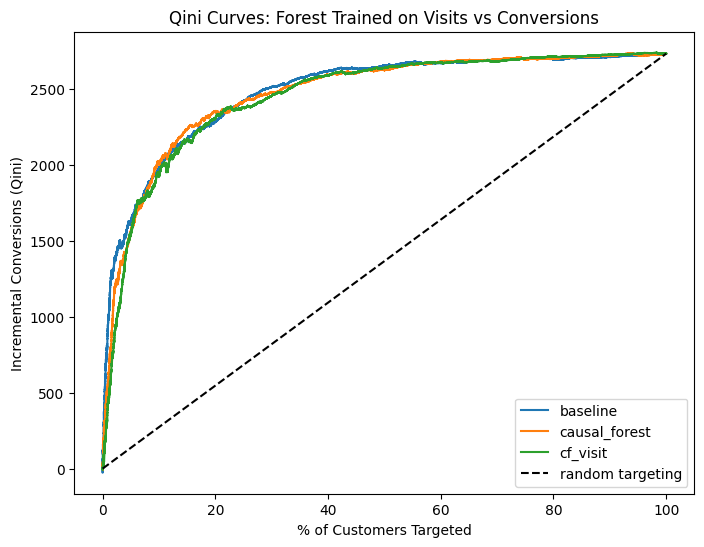

In [43]:
plt.figure(figsize=(8, 6))

for col in visit_cols:
    curve = uplift_curve(results, col)
    plt.plot(curve['pct_targeted'] * 100, curve['qini'], label=col)

last_qini = uplift_curve(results, 'baseline')['qini'].iloc[-1]
plt.plot([0, 100], [0, last_qini], 'k--', label='random targeting')

plt.xlabel('% of Customers Targeted')
plt.ylabel('Incremental Conversions (Qini)')
plt.title('Qini Curves: Forest Trained on Visits vs Conversions')
plt.legend()
plt.show()

**Result:**

- **Effect on visits:** the visit rate is 4.85% in the treatment group vs 3.82% in the control group, an effect of 1.03 pp (about a 27% lift). That's about 9 times the effect on conversions.
- The forest trained on visits predicts a mean effect of 0.68 pp on the test set, while the observed effect is 1.02 pp, so it underestimates the size of the visit effect by about a third.
- Its rank correlation with the conversion forest is 0.92, so the two forests rank customers in a very similar order.
- **On conversion:** the visit forest ties the baseline in most places, but it's slightly and significantly **worse** on Qini AUC and in the top 30%. In the Qini plot it starts slower than the other two in the first ~5% of customers, and after that the three curves are almost the same.
- So training on visits doesn't help here. With the full data there are already enough conversions for the conversion forest. Visits might help more with small data (for example the 1% subset in Extra 4), but I didn't test that.
- This section took about 2 hours to run (41 minutes of cross-fitting, 50 minutes for the forest and 29 minutes for the bootstrap).

### Conclusion

- **Effect of the campaign:** being assigned to the campaign increases conversion by about **0.09 pp** (Double ML: 0.089 pp, 95% CI [0.083, 0.095]), a relative lift of about **46%**. The raw difference (0.115 pp) gives the campaign about 0.03 pp too much credit, because the treated group had slightly more customers who would convert anyway.
- **Effect of seeing the ad:** only 3.6% of the treatment group saw the ad. For them, seeing it increases conversion by about **2.5 pp**, which almost doubles their conversion rate. This is a bit lower than the 3.1 pp from the randomized comparison in `Modeling_sample_2.ipynb`, because that used the raw difference.
- **Targeting:** the effect is very concentrated. The top 10% of customers (ranked by the baseline or the causal forest) have about 7 times the average uplift and give about 75% of the incremental conversions (from the Qini curve). The top 20% give about 85%.
- **Causal models vs the baseline:** even with 14 million customers, the causal forest only ties the simple baseline, and Double ML is worse. Combining the forest with the baseline, training it on visits, or giving it more data didn't change this.
- **Why:** the customers who respond most to the campaign are the ones who are most likely to convert anyway. They are much more likely to be shown the ad and they respond more when they see it. So ranking by how likely customers are to convert is almost the same as ranking by uplift.
- **Where the causal forest still helps:** its predicted effect sizes match the observed uplift well, and the customers it is confident about really do respond. So it's useful for estimating how many extra conversions a campaign will bring, even if it doesn't rank customers better than the baseline. The linear Double ML predictions are less reliable (its negative predictions aren't real).
- **Limitations:** this is one campaign on one dataset with anonymized features. For each data size in Extra 4 I only used one subset. The effect of seeing the ad assumes that being assigned only matters through seeing the ad.

### Saving the Results

- I save the Double ML and causal forest scores for the test customers, the average effect estimates, and the data size results from Extra 4.
- I add `_full` to the file names so they don't overwrite the files from `Causal_Forest_DML_PSM.ipynb`.
- These test customers are not the same as in `Modeling_sample_2.ipynb`, so these scores can't be added to the comparison there.

In [44]:
results[['treatment', 'conversion', 'dml_linear', 'causal_forest']].to_parquet('causal_model_scores_full.parquet', index=False)

(ate * 100).round(4).to_csv('average_effect_estimates_full.csv')
size_results.to_csv('data_size_results_full.csv', index=False)

print('Saved causal_model_scores_full.parquet, average_effect_estimates_full.csv and data_size_results_full.csv')

Saved causal_model_scores_full.parquet, average_effect_estimates_full.csv and data_size_results_full.csv
